# 02 · Linear regression from first principles

Before trusting `statsmodels` with a model that sets a bank's capital, it helps to know exactly what it computes. This notebook rebuilds every number in a regression table from linear algebra, on the real data: card losses explained by the labour market and interest rates.

| Section | Concept | Implemented in |
|---|---|---|
| 1 | Normal equation, and why it is solved with QR rather than a matrix inverse | `ols_scratch.fit_ols` |
| 2 | Gradient descent, feature scaling and learning-rate choice | `ols_scratch.fit_gradient_descent` |
| 3 | Standard errors: classical, White (HC), Newey-West (HAC) | `ols_scratch.newey_west` |
| 4 | t-tests, the overall F-test, nested-model F-tests, R², AIC/BIC | `f_test_nested`, `information_criteria` |
| 5 | Confidence interval vs prediction interval | by hand |
| 6 | Frisch–Waugh–Lovell theorem: what "holding other variables constant" means | by hand |
| 7 | Leverage and Cook's distance | `leverage`, `cooks_distance` |

Every result is checked against `statsmodels`; the same checks run in CI (`tests/test_ols_scratch.py`).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

from ukstress.features.build import covid_dummy, logit_pct, trailing_loss_rate
from ukstress.ingest.build_panel import build_macro, build_panel
from ukstress.models.ols_scratch import (
    cooks_distance, f_test_nested, fit_gradient_descent, fit_ols, information_criteria, leverage, newey_west,
)
from ukstress.viz import BLUE, GREY, ORANGE, fig_title, save, set_style, subtitle

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.width", 160, "display.precision", 4)

panel, macro = build_panel(), build_macro()
y_rate = trailing_loss_rate(panel, "credit_card")
df = pd.DataFrame({
    "y": pd.Series(logit_pct(y_rate), index=y_rate.index),
    "d_unemp_L4": macro["unemployment_chg_yoy"].shift(4),
    "bank_rate_L8": macro["bank_rate"].shift(8),
    "covid": covid_dummy(macro.index),
}).dropna().loc["1994Q2":]
y = df["y"].values
X = np.column_stack([np.ones(len(df)), df[["d_unemp_L4", "bank_rate_L8", "covid"]].values])
names = ["const", "d_unemp_L4", "bank_rate_L8", "covid"]
print(f"n = {len(y)} quarters ({df.index[0]} to {df.index[-1]}), k = {X.shape[1]} parameters")

n = 129 quarters (1994Q2 to 2026Q2), k = 4 parameters


**Model used throughout:** logit of the trailing card loss rate on the change in unemployment four quarters earlier, Bank Rate two years earlier, and a COVID-regime dummy. The model is chosen for teaching, not selected; selection is notebook 03.

## 1. The normal equation
OLS minimises the residual sum of squares $\lVert y - X\beta \rVert^2$. Setting the gradient $-2X'(y - X\beta)$ to zero gives
$$\hat\beta = (X'X)^{-1}X'y.$$
Inverting $X'X$ directly is numerically risky: its condition number is the *square* of $X$'s, so near-collinear regressors lose twice as many digits. Production code factorises $X = QR$ (Q orthonormal, R upper-triangular) and solves $R\hat\beta = Q'y$.

In [2]:
beta_inv = np.linalg.inv(X.T @ X) @ X.T @ y
Q, R = np.linalg.qr(X)
beta_qr = np.linalg.solve(R, Q.T @ y)
ref = sm.OLS(y, X).fit()
pd.DataFrame({"inverse (X'X)^-1 X'y": beta_inv, "QR": beta_qr, "statsmodels": ref.params}, index=names)

,inverse (X'X)^-1 X'y,QR,statsmodels
const,-3.1029,-3.1029,-3.1029
d_unemp_L4,0.5326,0.5326,0.5326
bank_rate_L8,-0.0594,-0.0594,-0.0594
covid,-0.5672,-0.5672,-0.5672


In [3]:
print(f"condition number of X:    {np.linalg.cond(X):,.0f}")
print(f"condition number of X'X:  {np.linalg.cond(X.T @ X):,.0f}  (= square of the above)")

condition number of X:    20
condition number of X'X:  414  (= square of the above)


## 2. Gradient descent
The same minimum can be reached iteratively: $\beta \leftarrow \beta - \eta \cdot \frac{2}{n} X'(X\beta - y)$. This is how linear models are trained when $X$ is too large to factorise, and it is the building block of every neural network later in the portfolio.

Gradient descent needs **standardised features**. With raw features, Bank Rate (0–7.5) and the COVID dummy (0/1) need very different step sizes, and any single learning rate is too large for one and too small for the other.

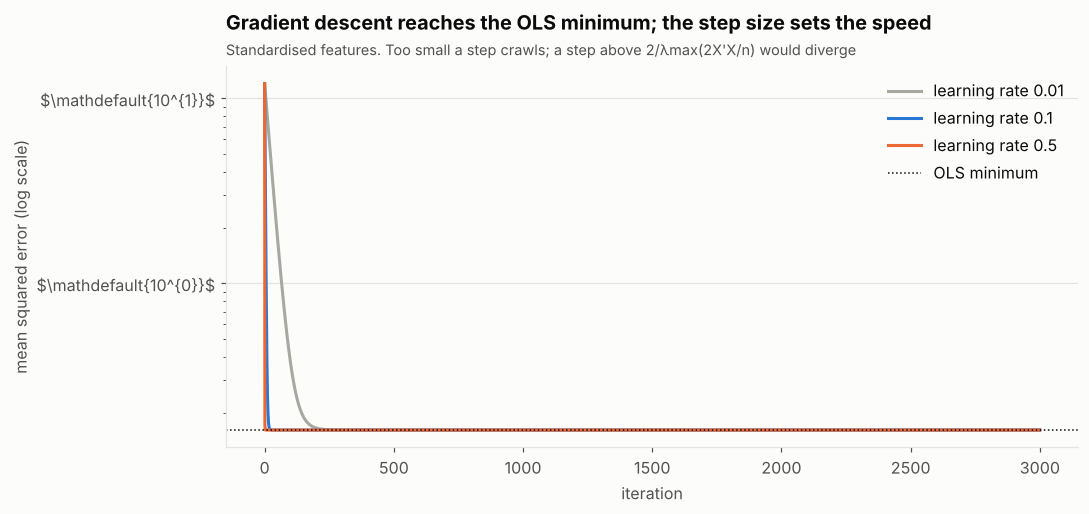

In [4]:
mu, sd = X[:, 1:].mean(0), X[:, 1:].std(0)
Xs = np.column_stack([np.ones(len(y)), (X[:, 1:] - mu) / sd])

fig, ax = plt.subplots(figsize=(10, 4.5))
for lr, colour in [(0.01, GREY), (0.1, BLUE), (0.5, ORANGE)]:
    _, hist = fit_gradient_descent(Xs, y, lr=lr, n_iter=3000, tol=0)
    ax.plot(hist, color=colour, label=f"learning rate {lr}")
ax.axhline(ref.ssr / len(y), color="#0b0b0b", ls=":", lw=1, label="OLS minimum")
ax.set_yscale("log")
ax.set_xlabel("iteration")
ax.set_ylabel("mean squared error (log scale)")
ax.set_title("Gradient descent reaches the OLS minimum; the step size sets the speed")
subtitle(ax, "Standardised features. Too small a step crawls; a step above 2/λmax(2X'X/n) would diverge")
ax.legend()
save(fig, "02_gradient_descent")
fig

In [5]:
beta_gd_s, hist = fit_gradient_descent(Xs, y, lr=0.1, n_iter=50_000, tol=1e-15)
# Undo the scaling: slope_j = slope_j_std / sd_j; intercept absorbs the means
slopes = beta_gd_s[1:] / sd
beta_gd = np.r_[beta_gd_s[0] - slopes @ mu, slopes]
eig = np.linalg.eigvalsh(2 * Xs.T @ Xs / len(y))
print(f"converged in {len(hist):,} iterations; max |GD - OLS| = {np.abs(beta_gd - beta_qr).max():.2e}")
print(f"largest stable learning rate = 2 / λmax = {2 / eig.max():.3f}")

converged in 111 iterations; max |GD - OLS| = 1.67e-07
largest stable learning rate = 2 / λmax = 0.784


## 3. Standard errors: three answers to "how sure are we?"
- **Classical:** $\hat\sigma^2 (X'X)^{-1}$. Assumes errors are independent with constant variance.
- **White (HC0/HC1):** $(X'X)^{-1} X'\,\mathrm{diag}(e^2)\,X (X'X)^{-1}$. Allows the variance to differ across quarters.
- **Newey–West (HAC):** adds weighted autocovariances of $x_t e_t$, so it is also valid when errors are correlated over time. That is the case here by construction: the trailing four-quarter target shares three quarters with its neighbour.

In [6]:
res = {c: fit_ols(X, y, cov_type=c, names=names) for c in ["nonrobust", "HC1", "HAC"]}
se = pd.DataFrame({c: r.bse for c, r in res.items()}, index=names)
se["statsmodels HAC"] = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 4}).bse
se["HAC / classical"] = se["HAC"] / se["nonrobust"]
se

,nonrobust,HC1,HAC,statsmodels HAC,HAC / classical
const,0.0636,0.0628,0.1111,0.1111,1.7484
d_unemp_L4,0.0542,0.0515,0.0913,0.0913,1.6857
bank_rate_L8,0.0142,0.0135,0.0242,0.0242,1.7076
covid,0.1670,0.1378,0.1703,0.1703,1.0197


In [7]:
rho = np.corrcoef(res["nonrobust"].resid[1:], res["nonrobust"].resid[:-1])[0, 1]
print(f"first-order autocorrelation of residuals: {rho:.2f}")
t_classical = res["nonrobust"].tvalues[1]
t_hac = res["HAC"].tvalues[1]
print(f"t-statistic on the unemployment change: classical {t_classical:.1f} vs Newey-West {t_hac:.1f}")

first-order autocorrelation of residuals: 0.92
t-statistic on the unemployment change: classical 9.8 vs Newey-West 5.8


With residual autocorrelation of 0.92, classical standard errors are far too small: Newey–West standard errors are about 1.7 times larger, cutting the t-statistic on the unemployment change by about 40%. **Every model in this project reports Newey–West standard errors.**

## 4. Hypothesis tests and fit statistics by hand

In [8]:
r0 = res["nonrobust"]
n, k = X.shape
rss, tss = r0.resid @ r0.resid, ((y - y.mean()) ** 2).sum()
manual = {
    "R²  = 1 - RSS/TSS": 1 - rss / tss,
    "adj R² = 1 - (1-R²)(n-1)/(n-k)": 1 - (rss / tss) * (n - 1) / (n - k),
    "overall F = (ESS/(k-1)) / (RSS/(n-k))": ((tss - rss) / (k - 1)) / (rss / (n - k)),
}
aic, bic = information_criteria(rss, n, k)
manual |= {"AIC = -2 lnL + 2k": aic, "BIC = -2 lnL + k ln n": bic}
pd.DataFrame({"by hand": list(manual.values()),
              "statsmodels": [ref.rsquared, ref.rsquared_adj, ref.fvalue, ref.aic, ref.bic]}, index=list(manual))

,by hand,statsmodels
R² = 1 - RSS/TSS,0.4592,0.4592
adj R² = 1 - (1-R²)(n-1)/(n-k),0.4462,0.4462
overall F = (ESS/(k-1)) / (RSS/(n-k)),35.3795,35.3795
AIC = -2 lnL + 2k,138.3882,138.3882
BIC = -2 lnL + k ln n,149.8275,149.8275


**Nested F-test:** does Bank Rate add anything once the labour market is in the model? Compare the residual sum of squares with and without it. This is the test behind every "drop a variable" decision in notebook 03.

In [9]:
restricted = fit_ols(np.delete(X, 2, axis=1), y)
f, p = f_test_nested(restricted.resid @ restricted.resid, rss, q=1, df_resid_full=n - k)
print(f"F = {f:.2f}, p = {p:.4f}  (statsmodels: {ref.compare_f_test(sm.OLS(y, np.delete(X, 2, axis=1)).fit())[:2]})")
print("With one restriction, F equals the squared classical t-statistic:", round(r0.tvalues[2] ** 2, 2))

F = 17.56, p = 0.0001  (statsmodels: (np.float64(17.563155864041736), np.float64(5.212990869230198e-05)))
With one restriction, F equals the squared classical t-statistic: 17.56


**A statistically significant coefficient with the wrong sign.** Bank Rate passes the F-test easily, but its coefficient is *negative*: higher rates two years earlier go with *lower* card losses. That is not economics, it is history. Rates were cut to 0.5% in 2009 just as losses peaked, and rose again in 2022–23 while losses were at record lows. A model that kept this coefficient would project that the stress scenario's 8% Bank Rate *reduces* losses. This is why banks impose **sign rules** before looking at fit, and why notebook 03 rejects any candidate whose coefficients contradict economics.

## 5. Confidence interval vs prediction interval
For a new quarter with regressors $x_0$:
- **Confidence interval** for the *expected* loss: $x_0'\hat\beta \pm t \cdot \sqrt{x_0' V x_0}$ (parameter uncertainty only)
- **Prediction interval** for the *actual* loss: $x_0'\hat\beta \pm t \cdot \sqrt{x_0' V x_0 + \hat\sigma^2}$ (adds the quarter's own shock)

Stress testing needs the prediction interval: a bank lives through one realisation, not the average one.

In [10]:
x0 = np.array([1.0, 2.0, 5.0, 0.0])  # unemployment up 2pp a year earlier, Bank Rate 5% two years earlier
V = r0.cov
fit0 = x0 @ r0.params
tq = stats.t.ppf(0.975, n - k)
se_mean, se_pred = np.sqrt(x0 @ V @ x0), np.sqrt(x0 @ V @ x0 + r0.sigma2)
to_rate = lambda z: 100 / (1 + np.exp(-z))  # noqa: E731
pred = sm.OLS(y, X).fit().get_prediction(x0[None, :]).summary_frame(alpha=0.05)
pd.DataFrame({
    "central": [to_rate(fit0)] * 2,
    "lower": [to_rate(fit0 - tq * se_mean), to_rate(fit0 - tq * se_pred)],
    "upper": [to_rate(fit0 + tq * se_mean), to_rate(fit0 + tq * se_pred)],
    "statsmodels lower": [to_rate(pred.mean_ci_lower[0]), to_rate(pred.obs_ci_lower[0])],
}, index=["95% confidence interval (card loss %)", "95% prediction interval (card loss %)"]).round(2)

,central,lower,upper,statsmodels lower
95% confidence interval (card loss %),8.83,7.04,11.02,7.04
95% prediction interval (card loss %),8.83,4.00,18.37,4.00


## 6. Frisch–Waugh–Lovell: what a multiple-regression coefficient means
The coefficient on the unemployment change in the full model equals the slope from a two-step procedure:
1. Regress card losses on the *other* regressors and keep the residuals (losses not explained by Bank Rate or COVID).
2. Regress the unemployment change on the other regressors and keep the residuals (unemployment news not explained by them).
3. Regress residual on residual.

This is what "the effect of unemployment, holding Bank Rate constant" means, and it is the basis of the partial regression plots used in notebook 04.

full-model coefficient: 0.532591   FWL two-step slope: 0.532591


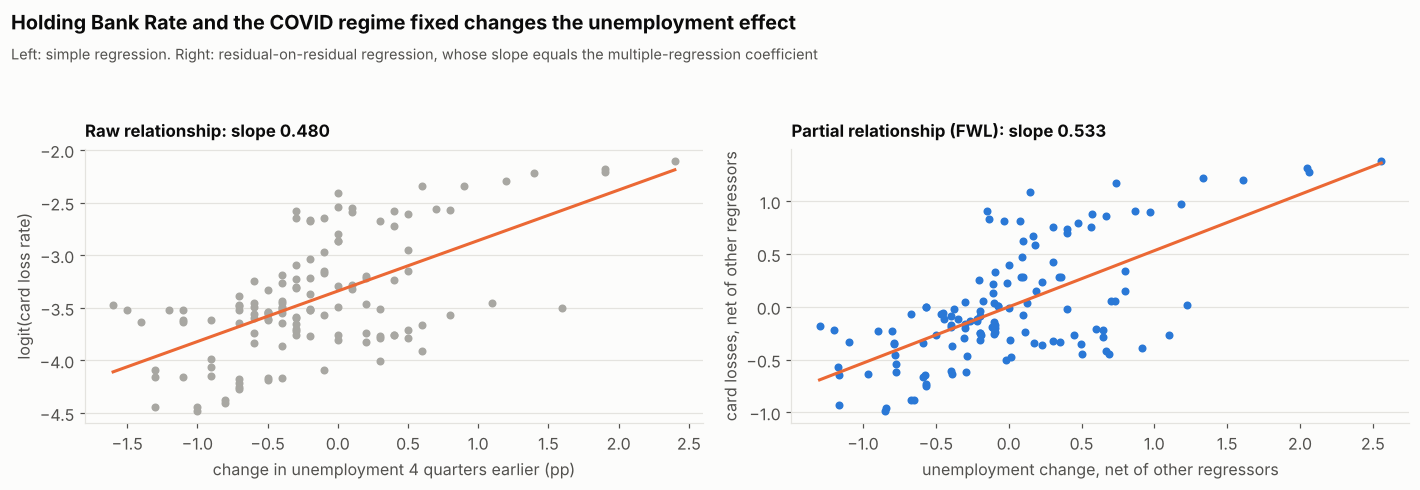

In [11]:
others = np.delete(X, 1, axis=1)
ey = y - others @ fit_ols(others, y).params
ex = X[:, 1] - others @ fit_ols(others, X[:, 1]).params
fwl_slope = (ex @ ey) / (ex @ ex)
print(f"full-model coefficient: {r0.params[1]:.6f}   FWL two-step slope: {fwl_slope:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(X[:, 1], y, s=18, color=GREY)
b_simple = fit_ols(X[:, :2], y).params
grid = np.linspace(X[:, 1].min(), X[:, 1].max(), 2)
axes[0].plot(grid, b_simple[0] + b_simple[1] * grid, color=ORANGE)
axes[0].set(xlabel="change in unemployment 4 quarters earlier (pp)", ylabel="logit(card loss rate)")
axes[0].set_title(f"Raw relationship: slope {b_simple[1]:.3f}", fontsize=11, pad=8)
axes[1].scatter(ex, ey, s=18, color=BLUE)
axes[1].plot(np.sort(ex), fwl_slope * np.sort(ex), color=ORANGE)
axes[1].set(xlabel="unemployment change, net of other regressors", ylabel="card losses, net of other regressors")
axes[1].set_title(f"Partial relationship (FWL): slope {fwl_slope:.3f}", fontsize=11, pad=8)
fig_title(fig, "Holding Bank Rate and the COVID regime fixed changes the unemployment effect",
          "Left: simple regression. Right: residual-on-residual regression, whose slope equals the multiple-regression coefficient")
save(fig, "02_fwl_partial_regression")
fig

## 7. Leverage and Cook's distance
- **Leverage** $h_{ii}$ (diagonal of the hat matrix $H = X(X'X)^{-1}X'$) measures how unusual a quarter's *regressors* are. The average is $k/n$.
- **Cook's distance** combines leverage with the size of the residual: how far *all* fitted values move if that quarter is dropped. A common rule of thumb flags $D_i > 4/n$.

In [12]:
h, D = leverage(X), cooks_distance(r0, X)
infl = sm.OLS(y, X).fit().get_influence()
print(f"max |leverage - statsmodels| = {np.abs(h - infl.hat_matrix_diag).max():.1e}; "
      f"max |Cook's - statsmodels| = {np.abs(D - infl.cooks_distance[0]).max():.1e}")
top = pd.DataFrame({"leverage": h, "Cook's D": D, "residual": r0.resid}, index=df.index)
top.sort_values("Cook's D", ascending=False).head(6).round(3)

max |leverage - statsmodels| = 2.5e-16; max |Cook's - statsmodels| = 1.0e-15


,leverage,Cook's D,residual
quarter,,,
2021Q4,0.169,0.151,-0.638
2022Q1,0.039,0.047,-0.855
2022Q2,0.037,0.046,-0.877
2021Q3,0.152,0.035,-0.329
1994Q2,0.066,0.032,-0.533
2020Q3,0.149,0.029,0.305


The most influential quarters are the end of the COVID regime (2021 Q4, high leverage because the dummy switches off) and early 2022, when losses were at record lows that this simple model cannot explain. Notebook 04 tests whether the selected models depend on them.

## Summary
- QR, gradient descent and `statsmodels` agree to machine precision; the from-scratch module is unit-tested against `statsmodels` in CI.
- The trailing target creates strong residual autocorrelation (0.92), which cuts honest t-statistics by about 40%: **Newey–West errors are mandatory for this problem.**
- A coefficient can be highly significant and economically wrong (Bank Rate here): **sign rules come before fit.**
- Stress projections need **prediction** intervals, which are far wider than confidence intervals.
- The FWL theorem defines what each coefficient in the satellite models means, and leads straight to the diagnostics in notebook 04.